# Around the Globe Quiz — Project Presentation

This notebook presents the data exploration, statistical analysis, and visualizations for the **Around the Globe Quiz** project developed for the *Coding for Data Science and Data Management* course.

## 1. Importing Libraries
We import the standard and third-party libraries used in the project:
- `json`: loads the geography dataset.
- `pandas`: handles tabular data structures, grouping, and CSV I/O.
- `numpy`: computes mathematical and statistical metrics (e.g. mean).
- `matplotlib.pyplot`: generates data visualizations.

In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Display charts inline within the notebook
%matplotlib inline

ModuleNotFoundError: No module named 'matplotlib'

## 2. Loading the Geography Dataset
The quiz generates questions dynamically using country data stored in `geography_data.json`. We load the dataset using Python's built-in `json` module.

In [ ]:
with open("geography_data.json", "r", encoding="utf-8") as file:
    geography_data = json.load(file)

print(f"Total countries loaded: {len(geography_data)}")
print("Sample country record:")
print(geography_data[0])

Total countries loaded: 25
Sample country record:
{'country': 'France', 'capital': 'Paris', 'continent': 'Europe', 'region': 'Western Europe'}


## 3. Dataset Inspection with Pandas
We convert the list of country dictionaries into a Pandas DataFrame to inspect the structure and distribution across continents and regions.

In [ ]:
geo_df = pd.DataFrame(geography_data)
geo_df.head()

,country,capital,continent,region
0,France,Paris,Europe,Western Europe
1,Japan,Tokyo,Asia,Eastern Asia
2,Canada,Ottawa,Americas,North America
3,Australia,Canberra,Oceania,Oceania
4,Brazil,Brasilia,Americas,South America


We inspect the number of countries per continent and total unique regions.

In [ ]:
print("Countries per continent:")
print(geo_df["continent"].value_counts())
print(f"\nTotal unique regions: {geo_df['region'].nunique()}")

Countries per continent:
continent
Europe      10
Asia         6
Americas     4
Africa       4
Oceania      1
Name: count, dtype: int64

Total unique regions: 14


## 4. Loading Quiz History with Pandas
Every completed game is automatically appended to `quiz_history.csv`. We read this file into a DataFrame.

In [ ]:
history_df = pd.read_csv("quiz_history.csv")
history_df

,date_time,difficulty,score,max_score,accuracy_pct
0,2026-11-06 23:07:28,Easy,0,5,0.0
1,2026-11-06 23:07:36,Medium,2,10,20.0
2,2026-11-06 23:07:44,Hard,0,15,0.0
3,2026-11-06 23:07:57,Easy,2,5,40.0
4,2026-11-06 23:15:15,Medium,10,10,100.0
5,2026-11-08 20:09:38,Hard,15,15,100.0
6,2026-11-12 17:01:27,Easy,1,5,20.0
7,2026-11-12 17:01:38,Medium,0,10,0.0
8,2026-11-12 17:01:49,Hard,3,15,20.0
9,2026-11-12 17:38:53,Easy,0,5,0.0


## 5. Statistical Analysis with NumPy and Pandas
We compute summary statistics across all games:
- Total games played using `len()`.
- Overall average accuracy using NumPy `np.mean()`.
- Highest accuracy achieved using Pandas `.max()`.
- Breakdown by difficulty using Pandas `.groupby()`.

In [ ]:
total_games = len(history_df)
average_accuracy = np.mean(history_df["accuracy_pct"])
highest_accuracy = history_df["accuracy_pct"].max()

print("=" * 40)
print(f"Total games played: {total_games}")
print(f"Overall average accuracy (NumPy): {average_accuracy:.2f}%")
print(f"Highest accuracy (Pandas):        {highest_accuracy:.2f}%")
print("=" * 40)

# Groupby analysis by difficulty
diff_counts = history_df.groupby("difficulty")["accuracy_pct"].count()
diff_averages = history_df.groupby("difficulty")["accuracy_pct"].mean()

print("\nPerformance by Difficulty (Pandas):")
for diff in ["Easy", "Medium", "Hard"]:
    if diff in diff_counts:
        print(f"  {diff:<6} -> Games: {diff_counts[diff]} | Average Accuracy: {diff_averages[diff]:.2f}%")

Total games played: 19
Overall average accuracy (NumPy): 40.00%
Highest accuracy (Pandas):        100.00%

Performance by Difficulty (Pandas):
  Easy   -> Games: 8 | Average Accuracy: 25.00%
  Medium -> Games: 5 | Average Accuracy: 48.00%
  Hard   -> Games: 6 | Average Accuracy: 53.33%


## 6. Visualizations with Matplotlib
We display three clear and separate charts:
1. **Bar chart:** Average accuracy by difficulty.
2. **Line chart:** Accuracy over time across all games.
3. **Pie chart:** Share of games played at each difficulty.

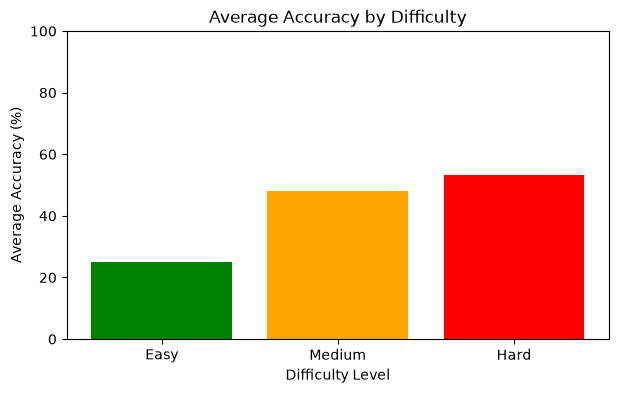

In [ ]:
# 1. Bar Chart: Average Accuracy by Difficulty
difficulties = ["Easy", "Medium", "Hard"]
avg_accuracies = []
for d in difficulties:
    if d in diff_averages:
        avg_accuracies.append(diff_averages[d])
    else:
        avg_accuracies.append(0.0)

plt.figure(figsize=(7, 4))
plt.bar(difficulties, avg_accuracies, color=["green", "orange", "red"])
plt.title("Average Accuracy by Difficulty")
plt.xlabel("Difficulty Level")
plt.ylabel("Average Accuracy (%)")
plt.ylim(0, 100)
plt.show()

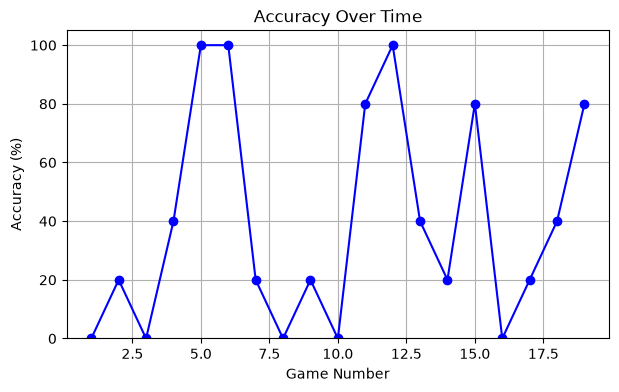

In [ ]:
# 2. Line Chart: Accuracy Over Time
game_numbers = list(range(1, len(history_df) + 1))

plt.figure(figsize=(7, 4))
plt.plot(game_numbers, history_df["accuracy_pct"], marker="o", color="blue")
plt.title("Accuracy Over Time")
plt.xlabel("Game Number")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)
plt.grid(True)
plt.show()

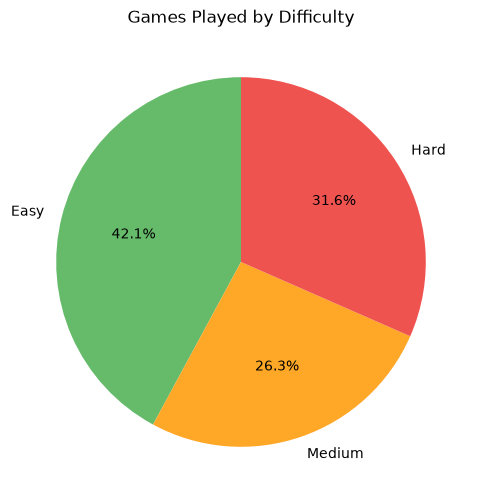

In [ ]:
# 3. Pie Chart: Games Played by Difficulty
difficulties = ["Easy", "Medium", "Hard"]
pie_labels = []
pie_counts = []
pie_colors = []
color_map = {"Easy": "#66bb6a", "Medium": "#ffa726", "Hard": "#ef5350"}

for d in difficulties:
    if d in diff_counts and diff_counts[d] > 0:
        pie_labels.append(d)
        pie_counts.append(diff_counts[d])
        pie_colors.append(color_map[d])

plt.figure(figsize=(6, 6))
plt.pie(pie_counts, labels=pie_labels, autopct="%1.1f%%", startangle=90, colors=pie_colors)
plt.title("Games Played by Difficulty")
plt.show()

## 7. Demonstrating the Quiz Generator
The full interactive game runs in the terminal using:
```bash
python quiz.py
```
Here, we demonstrate the question-generation engine from `quiz.py` by generating a sample question for each difficulty level. Notice how the distractor options adapt to the selected difficulty.

In [ ]:
from quiz import generate_capital_question

for diff in ["Easy", "Medium", "Hard"]:
    sample_q = generate_capital_question(geography_data, diff)
    print(f"[{diff.upper()} QUESTION]")
    print(sample_q["question"])
    print(f"  A) {sample_q['A']}")
    print(f"  B) {sample_q['B']}")
    print(f"  C) {sample_q['C']}")
    print(f"  D) {sample_q['D']}")
    print(f"  -> Correct Answer: {sample_q['answer']} ({sample_q[sample_q['answer']]})\n")

[EASY QUESTION]
What is the capital of Canada?
  A) Ottawa
  B) Cairo
  C) Canberra
  D) Stockholm
  -> Correct Answer: A (Ottawa)

[MEDIUM QUESTION]
What is the capital of South Africa?
  A) Cairo
  B) Nairobi
  C) Rabat
  D) Pretoria
  -> Correct Answer: D (Pretoria)

[HARD QUESTION]
What is the capital of South Korea?
  A) Tokyo
  B) Seoul
  C) New Delhi
  D) Bangkok
  -> Correct Answer: B (Seoul)

